# Phase 7: Test evaluation

We scored the locked models, the exploratory models declared before test and every baseline once on the test split (119 pairs from 14 donors; one scoring run, and a second, presentation-only run with display-only code changes reproduced every result file byte for byte), with the hypotheses, comparators and wordings fixed in advance. Hypothesis H1, that the strictly unpaired CycleGAN (M1) lies beyond the unpaired accuracy–realism frontier, is not distinguishable from the frontier in single-cell → bulk (margin +0.105, 95% CI −0.259 to 0.290) and places M1 inside the frontier in bulk → single-cell (−0.372, 95% CI −0.705 to −0.006); on test, real training profiles drawn at random also pass the frontier in both directions, and in single-cell → bulk M1 identifies its sample within the donor less often than its mean-shift start, the reverse of validation. Hypothesis H2 is supported in both directions: the weakly paired model (M2) exceeds M1 in marker-probe composition R² by +0.174 (95% CI 0.108–0.331) and +0.140 (95% CI 0.079–0.267), with the single-cell → bulk result labeled as partly fitting its training readout. Paired ridge + spread is far more accurate than either GAN (centered R² +0.375, 95% CI 0.302–0.478, and +0.515, 95% CI 0.406–0.682, over M1). The exploratory model with cross-fitted composition labels (B-cf, from networks that never saw the labeled donor's own pair) exceeds M1 in composition with averaged weights (+0.169, 95% CI 0.122–0.286; +0.115, 95% CI 0.064–0.240), not distinguishable from M2 with averaged weights, and carries the label that it partly fits its training readout.

## 1. Aim

This phase answers the project's three questions once, on donors no model, setting or analysis has seen: does the strictly unpaired CycleGAN translate beyond what blending unpaired baselines reaches (H1), does composition supervision through pair-trained networks improve composition (H2), and how far are both from a paired reference (H3)? It also reports, as exploratory and without claims, the composition-label model declared in Phase 6 and the test version of "what pairs buy".

## 2. Data

- **Scoring: the test split** (119 pairs, 14 donors; every test donor has at least two draws), read by a single scoring run; a later presentation-only re-run, logged in `results/phase7/test_touch.json`, changed only the display and reproduced every CSV byte for byte. Nothing was selected, tuned or refit on it: every model, setting, checkpoint, threshold, wording and bootstrap seed was fixed on training and validation data before the test rows were read.
- **Fit on training data only:** the evaluators (Phase 1, training targets), the composition networks and marker probes (Phase 2), the frontier's unpaired members (mean shift, ComBat, CORAL and the training-target mean, on the training halves of each halving), the paired baselines (all 582 training pairs), the pair-budget regressions (the Phase 5 donor sets of half A) and the optimal-transport map (the halving-0 halves).
- **Translation models:** the locked M1 and M2 at their chosen checkpoints (raw weights, seeds 0–2), their halving-1 counterparts, and the averaged-weight (exponential moving average) M1, M2, B-cf and pair-budget models at steps 15,000, 17,500 and 20,000 (seeds 6–8), each checked against its registry hash or run record before scoring.

## 3. Methods

**Metrics** (defined in full in Phase 1, §3, and Phase 3, §3). Centered R² (accuracy) is the median over pairs of $1 - \lVert \hat y - y\rVert^2 / \lVert y - \mu\rVert^2$, with $\mu$ the target domain's training mean. Realism is $1 - 2\,\lvert \text{AUROC} - 0.5\rvert$ of a classifier two-sample test (Lopez-Paz and Oquab, 2017) on the top 10 target principal components and their squares, in donor-grouped folds. The **unpaired frontier** $F(r)$ is the best realism at centered R² of at least $r$ among blends of two of mean shift, ComBat (Johnson et al., 2007), CORAL (Sun et al., 2016) and the training-target mean, fit on the training halves; a model's **margin** is its realism minus $F$ at its accuracy. Marker-probe composition R² is the mean over six cell-type classes of the per-class R² of a ridge readout of composition from 28 lineage markers (Phase 2).

**Hypotheses** (fixed before Phase 3, per direction; four primary intervals, uncorrected). M1 is the strictly unpaired CycleGAN (Zhu et al., 2017) and M2 the weakly paired one, which adds a composition loss through pair-trained composition networks (Phase 3).
- **H1:** M1's margin, with each seed's margin taken against the frontier and the three averaged. *CI above 0:* "supported on halving 0", qualified "not robust to the training split" if the halving-1 test margin is at or below 0; *including 0:* "not distinguishable from the unpaired frontier"; *below 0:* "inside the unpaired frontier". The earlier per-metric form, superseded on 2026-10-07 by the frontier form (M1 against mean shift and CORAL in single-cell → bulk, ComBat and mean shift in bulk → single-cell, on accuracy and realism separately) is reported in one line.
- **H2:** M2 minus M1 in marker-probe composition R²; "supported" if the CI is above 0.
- **H3:** ridge + spread minus M1 and M2 on centered R², realism and composition, with no claim.

**Uncertainty.** Paired donor bootstrap: 1,000 resamples of the 14 test donors (seed 0), with every metric recomputed on each resample and a model's members averaged inside it; for H1 the frontier itself is rebuilt from the members on each resample. A resampled donor's copies keep its donor ID, so they share a fold in the classifier test.

**Exploratory, declared before test** (no claims). B-cf, the weakly paired model whose composition labels come from networks that never saw the labeled donor (Phase 5), against M1 and M2 with averaged weights; entropic optimal transport (Cuturi, 2013) with one conditional draw per source (OT-s, a retrieval model; Phase 6); a no-information reference (one real training-half profile drawn uniformly per source); another draw of the same donor; and the pair-budget grid (Phase 6, §4.5). B-cf's design used the validation results of Phases 3–5.

## 4. Results

The first code cell records the setup stamp, checks, before any test row is read, that the analysis code is the version fixed before the test run, and loads the frozen models and evaluators.

In [1]:
import os, sys, json, warnings, hashlib, pickle, time, datetime, subprocess
from pathlib import Path
os.environ["PYTHONWARNINGS"] = "ignore:An input array is constant"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgm").is_dir())   # repo root, wherever this runs from
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.linalg import LinAlgWarning
from scipy.stats import ConstantInputWarning

from dgm import paths
from dgm import analysis as an
from dgm import composition as comp
from dgm import ot
from dgm import testeval as te
from dgm import translation as tr
from dgm.baselines import CORAL, ComBat, MeanShift, PairedMLP, Ridge, RidgePCCalibration, RidgeSpread
from dgm.data import train_halves
from dgm.frontier import MEAN, envelope, frontier_margin, frontier_realism
from dgm.metrics import GRANULOCYTE, cosine_matrix, partner_ranks, within_donor_ranks
from dgm.models import canonical_hash, list_hash, pairs_hash
from dgm.notebook import setup
from dgm.plotting import DOMAIN, INK, INK_2, MUTED, SERIES, THRESHOLD, figure, label, panel_labels, save_show

warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", category=ConstantInputWarning)
info = setup(seed=0, notebook="phase7_test_evaluation.ipynb")
comp.deterministic()

_dry, _test = os.environ.get("PHASE7_DRY", ""), os.environ.get("PHASE7_TEST", "")
assert (_dry, _test) in (("1", ""), ("", "1")), f"set exactly one of PHASE7_DRY=1 (validation) or PHASE7_TEST=1 (the test run); got {(_dry, _test)}"
DRY = _dry == "1"                                             # dry run: validation stands in for test; no test row is read
NBOOT = int(os.environ.get("PHASE7_NBOOT", "1000"))
assert DRY or NBOOT == 1000, "the test run uses the 1,000 resamples fixed in the spec"
WORKERS = 6
RESULTS = paths.results_dir(7) if not DRY else paths.PROCESSED / "phase7" / "dry_results"
FIG = paths.results_dir(7, "figures") if not DRY else RESULTS / "figures"
CACHE = paths.PROCESSED / "phase7"; FITS = CACHE / "fits"
for p_ in (RESULTS, FIG, FITS):
    p_.mkdir(parents=True, exist_ok=True)

def code_hash():
    """The analysis code: the shared modules, the Phase 7 tests and this notebook's code cells."""
    h = hashlib.sha256()
    for f in sorted((ROOT / "dgm").glob("*.py")) + [ROOT / "tests" / "test_phase7.py"]:
        h.update(f.read_bytes())
    nb = json.loads((ROOT / "notebooks" / "phase7_test_evaluation.ipynb").read_text())
    h.update("".join("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code").encode())
    return h.hexdigest()[:16]
CODE = code_hash()
if not DRY:                                                   # the test run must use the audited code, before any test row is read
    audited = (paths.results_dir(7) / "audited_code_hash.txt").read_text().strip()
    assert CODE == audited, f"code {CODE} is not the audited code {audited}: no test row is read"
    touch = paths.results_dir(7) / "test_touch.json"
    log = json.loads(touch.read_text()) if touch.exists() else []
    log.append({"time": datetime.datetime.now().isoformat(timespec="seconds"), "commit": info["commit"], "code": CODE, "nboot": NBOOT,
                "dry": DRY, "workers": WORKERS, "notebook_source": info.get("notebook_source")})
    touch.write_text(json.dumps(log, indent=1) + "\n")
print(f"{'DRY RUN on validation' if DRY else 'TEST RUN'}; code {CODE}; resamples {NBOOT}")

def show_caption(name):
    f = FIG / "captions.md" if not DRY else paths.results_dir(7, "figures") / "captions.md"
    text = f.read_text() if f.exists() else ""
    if f"\n## {name}\n" in text:
        display(Markdown(text.split(f"\n## {name}\n", 1)[1].split("\n## ", 1)[0].strip()))

ctx0 = tr.SoundLife(0)
P = ctx0.pairs
E = te.split_rows(P, DRY)                                     # the evaluation rows (validation in a dry run, test otherwise)
tr_idx = P.idx("train")
ha, hb = ctx0.half_a, ctx0.half_b
ha1, hb1 = train_halves(P, 1)
DIRS = tr.DIRECTIONS
digest = pairs_hash(P)
src = {"S->B": P.x_sc[E], "B->S": P.x_bulk[E]}
tgt = {"S->B": P.x_bulk[E], "B->S": P.x_sc[E]}
donors_E, C_E, age_E = P.donor_ids[E], P.composition[E], P.age_group[E]
n_E = len(E)
NG = P.x_sc.shape[1]
BOOT = an.donor_boot(donors_E, NBOOT, seed=0)
print(f"evaluation set: {n_E} pairs, {len(np.unique(donors_E))} donors")

<env>/lib/python3.10/site-packages/torch/cuda/__init__.py:182: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:109.)
  return torch._C._cuda_getDeviceCount() > 0


commit: e54ae6a | notebook_source: d041ca6c732e (= HEAD) | python: 3.10.14 | numpy: 1.26.4 | seed: 0 | torch: 2.8.0+cu129 | cuda: False
TEST RUN; code 15367eb6ad547608; resamples 1000


evaluation set: 119 pairs, 14 donors


In [2]:
# Frozen fits, cached by their training inputs (never by evaluation rows): the frontier members on each halving, the
# paired baselines on all training pairs, and the pair-budget regressions on Phase 5's donor sets.
BASE_CODE = hashlib.sha256((ROOT / "dgm" / "baselines.py").read_bytes()).hexdigest()[:12]
def fitted(name, d, rows_s, rows_t, make):
    key = json.dumps([name, d, list_hash(np.sort(rows_s).tolist()), list_hash(np.sort(rows_t).tolist()), digest, BASE_CODE])
    comp.assert_train_only(P, rows_s); comp.assert_train_only(P, rows_t)       # fits never see evaluation rows (checked on every call)
    path = FITS / f"{hashlib.sha256(key.encode()).hexdigest()[:16]}.pkl"
    if path.exists():
        return pickle.loads(path.read_bytes())
    m = make()
    path.write_bytes(pickle.dumps(m))
    return m
def st_of(d):
    return (P.x_sc, P.x_bulk) if d == "S->B" else (P.x_bulk, P.x_sc)

def members_of(h):
    a_, b_ = (ha, hb) if h == 0 else (ha1, hb1)
    out = {}
    for d in DIRS:
        s_all, t_all = st_of(d)
        rs, rt = (a_, b_) if d == "S->B" else (b_, a_)
        out[d] = {cls().name: fitted(cls().name, d, rs, rt, lambda cls=cls: cls().fit(s_all[rs], t_all[rt])).translate(src[d])
                  for cls in (MeanShift, ComBat, CORAL)}
        out[d][MEAN] = np.tile(t_all[rt].mean(0), (n_E, 1))
    return out
MEMBERS = {0: members_of(0), 1: members_of(1)}

PAIRED = {}
for d in DIRS:
    s_all, t_all = st_of(d)
    D_ = P.donor_ids
    PAIRED[(d, "ridge")] = [fitted("ridge", d, tr_idx, tr_idx, lambda: Ridge().fit(s_all[tr_idx], t_all[tr_idx], D_[tr_idx])).translate(src[d])]
    PAIRED[(d, "ridge + spread")] = [fitted("ridge + spread", d, tr_idx, tr_idx, lambda: RidgeSpread().fit(
        s_all[tr_idx], t_all[tr_idx], D_[tr_idx], comp=P.composition[tr_idx], age=P.age_group[tr_idx], genes=ctx0.genes, direction=d)).translate(src[d])]
    PAIRED[(d, "ridge + PC calibration")] = [fitted("ridge + PC calibration", d, tr_idx, tr_idx,
                                                    lambda: RidgePCCalibration().fit(s_all[tr_idx], t_all[tr_idx], D_[tr_idx])).translate(src[d])]
    PAIRED[(d, "paired MLP")] = [fitted(f"paired MLP seed {s}", d, tr_idx, tr_idx, lambda s=s: PairedMLP(seed=s).fit(s_all[tr_idx], t_all[tr_idx], D_[tr_idx])).translate(src[d])
                                 for s in (0, 1, 2)]
print("fits ready")

fits ready


In [3]:
# The translation models, each checked against its registry or its run's provenance before scoring.
KEEP = (15000, 17500, 20000)
M1c = tr.config(lambda_cyc=20.0, identity=True); M2c = tr.config(lambda_cyc=20.0, identity=True, lambda_task=10.0)
DEF5 = dict(ema=0.999, keep_states=KEEP)
KEY5 = "41dab869bea05335"
P3REG = json.loads((paths.results_dir(3) / "models.json").read_text())
def locked_states(m, h):
    out = []
    for s in (0, 1, 2):
        name = f"{m}_seed{s}" if h == 0 else f"{m}_halving1_seed{s}"
        st = torch.load(paths.REPO / "data" / "models" / "phase3" / f"{name}.pt", weights_only=False)["state"]
        assert canonical_hash(st) == P3REG[name]["canonical_hash"], name
        out.append(st)
    return out
def cached_run(cfg, seed):
    c = tr.config(**cfg)
    name = hashlib.sha256(json.dumps([KEY5, c, seed, 0], sort_keys=True, default=str).encode()).hexdigest()[:16]
    r = pickle.loads((paths.PROCESSED / "phase5" / f"run_{name}.pkl").read_bytes())
    assert r["code_key"] == KEY5 and json.dumps(r["cfg"], sort_keys=True, default=str) == json.dumps(c, sort_keys=True, default=str)
    return r
runs5 = pd.read_csv(paths.results_dir(5) / "runs_val.csv")
EMA_CFG = {"M1 (EMA)": (dict(M1c, **DEF5), "M1"), "M2 (EMA)": (dict(M2c, **DEF5), "M2"),
           "B-cf (EMA)": (dict(M2c, task_nets="crossfit", **DEF5), "B-cf cross-fitted labels"),
           **{f"B-k{k} (EMA)": (dict(M2c, task_nets=f"k{k}", **DEF5), f"B-k{k} labels from {k} donors") for k in (4, 8, 16, 33)}}
EMA_RUNS = {}
for name, (cfg, cond) in EMA_CFG.items():
    EMA_RUNS[name] = [cached_run(cfg, s) for s in (6, 7, 8)]
    for r in EMA_RUNS[name]:                                   # provenance: last-quarter means equal Phase 5's per-run table
        row = runs5[(runs5.condition == cond) & (runs5.seed == r["seed"])].iloc[0]
        for d in DIRS:
            lq = np.mean([e["ema"][f"{d} r2_centered"] for e in r["evals"] if e["step"] >= 15000])
            assert abs(lq - row[f"{d} r2_centered"]) < 1e-9, (name, r["seed"], d)
STATES = {"M1": locked_states("M1", 0), "M2": locked_states("M2", 0), "M1, halving 1": locked_states("M1", 1), "M2, halving 1": locked_states("M2", 1),
          **{n: [r["kept_ema"][k] for r in rs for k in KEEP] for n, rs in EMA_RUNS.items()}}
def translate(states, d):
    out = []
    for stt in states:
        sb, bs = tr.load_generators(stt, NG, 512)
        with torch.no_grad():
            out.append((sb if d == "S->B" else bs)(torch.as_tensor(np.asarray(src[d], np.float32))).numpy())
    return out
OUT = {(n, d): translate(s, d) for n, s in STATES.items() for d in DIRS}

# Exploratory comparators: OT-s (eps 0.3 on the halving-0 halves, draw seeds 0-2), a no-information reference (one
# training-half target drawn uniformly per source, seeds 0-2) and another draw of the same donor.
for d in DIRS:
    a0, b0 = ctx0.init[d]
    hs, ht = (ctx0.xs, ctx0.xb) if d == "S->B" else (ctx0.xb, ctx0.xs)
    m = ot.EntropicOT(0.3, lambda x, a0=a0, b0=b0: np.maximum(x * a0 + b0, 0)).fit(np.asarray(hs, float), np.asarray(ht, float))
    OUT[("OT-s", d)] = [m.sample(np.asarray(src[d], float), seed=s)[0] for s in (0, 1, 2)]
    OUT[("no-information reference", d)] = [np.asarray(ht, float)[np.random.default_rng([s, 7]).integers(len(ht), size=n_E)] for s in (0, 1, 2)]
    OUT[("same-donor reference", d)] = [tgt[d][an.other_draw(donors_E)]]
    for k, v in MEMBERS[0][d].items():
        OUT[(k, d)] = [v]
    for k in ("ridge", "ridge + spread", "ridge + PC calibration", "paired MLP"):
        OUT[(k, d)] = PAIRED[(d, k)]
print({k: len(v) for k, v in OUT.items() if k[1] == "S->B"})

{('M1', 'S->B'): 3, ('M2', 'S->B'): 3, ('M1, halving 1', 'S->B'): 3, ('M2, halving 1', 'S->B'): 3, ('M1 (EMA)', 'S->B'): 9, ('M2 (EMA)', 'S->B'): 9, ('B-cf (EMA)', 'S->B'): 9, ('B-k4 (EMA)', 'S->B'): 9, ('B-k8 (EMA)', 'S->B'): 9, ('B-k16 (EMA)', 'S->B'): 9, ('B-k33 (EMA)', 'S->B'): 9, ('OT-s', 'S->B'): 3, ('no-information reference', 'S->B'): 3, ('same-donor reference', 'S->B'): 1, ('mean shift', 'S->B'): 1, ('ComBat', 'S->B'): 1, ('CORAL', 'S->B'): 1, ('training mean', 'S->B'): 1, ('ridge', 'S->B'): 1, ('ridge + spread', 'S->B'): 1, ('ridge + PC calibration', 'S->B'): 1, ('paired MLP', 'S->B'): 3}


In [4]:
# Scoring: every Evaluator metric (mean over a model's members), marker-probe and network composition, granulocyte correlation.
ev = ctx0.ev
gran_idx = [ctx0.genes.index(g) for g in GRANULOCYTE if g in ctx0.genes]
def r2_samples(y, d):
    return 1 - ((y - tgt[d]) ** 2).sum(1) / ((tgt[d] - ev[d].mean_) ** 2).sum(1)
def realism_of(y, d):
    return 1 - 2 * abs(ev[d].score(y, tgt[d], C_E, age_E, donors_E, ctx0.classes)[0]["c2st_auroc"] - 0.5)
def within1(y, d):
    w = within_donor_ranks(cosine_matrix(y - ev[d].mean_, tgt[d] - ev[d].mean_), donors_E)
    return np.where(np.isnan(w), np.nan, (w == 1).astype(float))
def score_set(ys, d, frontier_points):
    rows = []
    for y in ys:
        m, _ = ev[d].score(y, tgt[d], C_E, age_E, donors_E, ctx0.classes)
        real = 1 - 2 * abs(m["c2st_auroc"] - 0.5)
        mg, kind = frontier_margin(frontier_points, m["r2_centered"], real)
        with torch.no_grad():
            net = comp.comp_r2(ctx0.nets[d](torch.as_tensor(np.asarray(y, np.float32))).numpy(), C_E)
        rows.append({**m, "realism": real, "margin": mg, "accuracy-kind margin": kind == "accuracy",
                     "marker composition R²": comp.comp_r2(ctx0.marker[d].predict(y), C_E), "network composition R²": net,
                     "granulocyte r": float(np.corrcoef(y[:, gran_idx].mean(1), tgt[d][:, gran_idx].mean(1))[0, 1]) if d == "S->B" else np.nan})
    return pd.DataFrame(rows).mean(numeric_only=True)

# The frontier on the full evaluation set for each halving (the point estimates), from the bootstrap module's exact scoring.
DD = {h: {d: te.DirectionData(members=MEMBERS[h][d], models={}, target=tgt[d], mu=ev[d].mean_, pca=ev[d].pca_, donors=donors_E) for d in DIRS} for h in (0, 1)}
FULL = {h: {d: te.resample(DD[h][d], np.arange(n_E)) for d in DIRS} for h in (0, 1)}
FRONT = {h: {d: FULL[h][d]["points"] for d in DIRS} for h in (0, 1)}
TOL_REAL = 1e-3          # Phase 1 ran at another thread count: AUROC ties can flip (as in Phase 4's frontier check)
if DRY:                                                       # the dry run reproduces Phase 1's validation frontier
    fr1 = pd.read_csv(paths.results_dir(1) / "frontier_val_halves.csv")
    for h in (0, 1):
        for d in DIRS:
            ref = fr1[(fr1.halving == h) & (fr1.direction == d)].reset_index(drop=True)
            got = FRONT[h][d]
            assert np.allclose(got["r2_centered"], ref["r2_centered"], atol=1e-6) and np.allclose(got["realism"], ref["realism"], atol=TOL_REAL), (h, d)
    print("dry run: frontier points reproduce Phase 1 on both halvings")

MODELS_SCORED = ["M1", "M2", "M1 (EMA)", "M2 (EMA)", "B-cf (EMA)", "mean shift", "ComBat", "CORAL", MEAN, "ridge", "ridge + spread",
                 "ridge + PC calibration", "paired MLP", "OT-s", "no-information reference", "same-donor reference"]
SC = {(n, d): score_set(OUT[(n, d)], d, FRONT[0][d]) for n in MODELS_SCORED for d in DIRS}
SC.update({(n, d): score_set(OUT[(n, d)], d, FRONT[1][d]) for n in ("M1, halving 1", "M2, halving 1") for d in DIRS})
if DRY:                                                       # the dry run reproduces the validation values of Phases 3, 5 and 6
    p3 = pd.read_csv(paths.results_dir(3) / "models_vs_baselines_val.csv")
    pm6 = pd.read_csv(paths.results_dir(6) / "plane_margins_val.csv")
    P3_KEY = P3REG["M1_seed0"]["code_key"]
    P3_KEYS = ("steps", "batch", "lr_g", "lr_d", "betas", "hidden", "lambda_cyc", "identity", "lambda_task", "warmup", "ramp",
               "noise_sd", "eval_every", "log_every", "shuffle_d")
    def p3_runs(m, h):
        cfg = {k: (M1c if m == "M1" else M2c)[k] for k in P3_KEYS}
        out = []
        for s_ in (0, 1, 2):
            name = hashlib.sha256(json.dumps([P3_KEY, cfg, s_, h], sort_keys=True, default=str).encode()).hexdigest()[:16]
            r_ = pickle.loads((paths.PROCESSED / "phase3" / f"run_{name}.pkl").read_bytes())
            assert r_["state_hash"] == P3REG[f"{m}_seed{s_}" if h == 0 else f"{m}_halving1_seed{s_}"]["canonical_hash"]
            out.append(r_)
        return out
    for d in DIRS:
        for m in ("M1", "M2"):
            r = p3[(p3.direction == label(d)) & (p3.method == f"{m} (mean of 3 seeds)")].iloc[0]
            assert abs(SC[(m, d)]["margin"] - r["margin at the chosen checkpoint"]) < TOL_REAL, (m, d)
            assert abs(SC[(m, d)]["marker composition R²"] - r["marker composition R²"]) < 1e-6, (m, d)
            assert abs(SC[(m, d)]["r2_centered"] - r["r2_centered"]) < 1e-9 and abs(SC[(m, d)]["realism"] - r["realism"]) < 1e-9, (m, d)
            want = np.mean([r_["best"][f"{d} margin"] for r_ in p3_runs(m, 1)])      # chosen checkpoints of the halving-1 runs
            assert abs(SC[(f"{m}, halving 1", d)]["margin"] - want) < TOL_REAL, (m, d, "halving 1")
        for n, key in (("M1 (EMA)", "M1, averaged weights (kept steps)"), ("B-cf (EMA)", "B-cf, averaged weights (kept steps)")):
            want = pm6[(pm6.direction == label(d)) & (pm6.model == key)]["margin"].iloc[0]
            assert abs(SC[(n, d)]["margin"] - want) < TOL_REAL, (n, d)
        ots = pd.read_csv(paths.results_dir(6) / "ot_sweep_val.csv")
        want = ots[(ots.variant == "OT-s") & (ots.eps == 0.3) & (ots.direction == label(d))]["margin"].iloc[0]
        assert abs(SC[("OT-s", d)]["margin"] - want) < TOL_REAL
    print("dry run: locked, halving-1, averaged-weight and OT-s values reproduce Phases 3, 5 and 6")

<env>/lib/python3.10/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
<env>/lib/python3.10/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


### 4.1 Hypothesis H1: the strictly unpaired model against the unpaired frontier

**M1 is not distinguishable from the unpaired frontier in single-cell → bulk and is inside it in bulk → single-cell; real profiles that carry no information about the source pass the frontier in both directions.**

**Table 7.1.** H1 on the 119 test pairs (14 donors): M1's margin (mean over the three locked seeds) with its donor-bootstrap 95% CI, the pre-stated reading, the kind of each seed's margin, the share of resamples in which every seed's margin was of the realism kind, M1's accuracy and realism, the frontier's realism at M1's accuracy and the halving-1 margin (point estimate, against the halving-1 frontier). **Table 7.2.** The superseded per-metric form of H1. **Table 7.3.** M1's within-donor top-1 rate (the share of samples whose translation is closest to its own partner among the donor's draws) against each unpaired map and its matched blend (the most realistic blend at M1's accuracy, solved on the full test set and held fixed), with paired CIs. **Table 7.4.** Reference profiles (the no-information reference, OT-s retrieval and another draw of the same donor) with the kind of each margin (realism, or an accuracy lead in centered-R² units when the profile is more accurate than every blend), and the real test targets read by each composition readout.

In [5]:
# The H1 bootstrap: on every resample the frontier is rebuilt from the halving-0 members and each M1 seed's margin is
# taken against it; M2 and ridge + spread are carried for the realism intervals of H3. Cached by code, rows and resamples.
for d in DIRS:
    DD[0][d] = te.DirectionData(members=MEMBERS[0][d], models={"M1": OUT[("M1", d)], "M2": OUT[("M2", d)], "ridge + spread": OUT[("ridge + spread", d)]},
                                target=tgt[d], mu=ev[d].mean_, pca=ev[d].pca_, donors=donors_E)
full = {d: te.resample(DD[0][d], np.arange(n_E)) for d in DIRS}
for d in DIRS:                                                 # the bootstrap module's model scores agree with the evaluator's
    assert abs(np.mean(full[d]["margins"]) - SC[("M1", d)]["margin"]) < 1e-9
bpath = CACHE / f"h1_boot_{'dry' if DRY else 'test'}_{CODE}_{NBOOT}.pkl"
if bpath.exists():
    boot = pickle.loads(bpath.read_bytes())
else:
    t0 = time.time()
    boot = te.run(DD[0], BOOT, workers=WORKERS)
    boot["minutes"] = (time.time() - t0) / 60
    bpath.write_bytes(pickle.dumps(boot))
print(f"bootstrap: {NBOOT} resamples x 2 directions in {boot['minutes']:.1f} minutes")

def q(v):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    return (np.quantile(v, 0.025), np.quantile(v, 0.975)) if len(v) else (np.nan, np.nan)
h1_rows = []
for d in DIRS:
    b = boot[d]
    margins = np.array([np.mean(r["margins"]) for r in b])
    all_real = np.array([all(k == "realism" for k in r["kinds"]) for r in b])
    lo, hi = q(margins)
    rlo, rhi = q(margins[all_real])
    est = float(np.mean(full[d]["margins"]))
    h1m = SC[("M1, halving 1", d)]["margin"]
    words = te.h1_wording(lo, hi)
    qualifier = te.h1_qualifier(lo, h1m)
    h1_rows.append({"direction": label(d), "margin": est, "95% CI": f"{lo:.3f} to {hi:.3f}", "reading": words + (f"; {qualifier}" if qualifier else ""),
                    "kinds of the seeds' margins (full set)": ", ".join(full[d]["kinds"]),
                    "share of resamples with all realism-kind margins": all_real.mean(), "share with any accuracy-kind margin": 1 - all_real.mean(),
                    "realism-margin 95% CI (realism-kind resamples)": f"{rlo:.3f} to {rhi:.3f}",
                    "M1 centered R²": np.mean([m[0] for m in full[d]["models"]["M1"]]), "M1 realism": np.mean([m[1] for m in full[d]["models"]["M1"]]),
                    "frontier at M1's accuracy": np.mean([frontier_realism(FRONT[0][d], m[0]) for m in full[d]["models"]["M1"]]),
                    "halving-1 margin (point estimate)": h1m,
                    "halving-1 margin in (0, 0.05]": bool(0 < h1m <= 0.05),
                    "no-information reference beyond the frontier": bool(SC[("no-information reference", d)]["margin"] > 0),
                    "settings compared": "M1: 12 settings × 3 seeds on validation"})
h1_tab = pd.DataFrame(h1_rows)
h1_tab.to_csv(RESULTS / "h1_test.csv", index=False)
display(h1_tab.style.format("{:.3f}", subset=["margin", "share of resamples with all realism-kind margins", "share with any accuracy-kind margin",
                                               "M1 centered R²", "M1 realism", "frontier at M1's accuracy", "halving-1 margin (point estimate)"])
        .hide(axis="index").set_caption("Table 7.1. Hypothesis H1 on test: M1's margin beyond the unpaired frontier"))

# The superseded per-metric H1 (fixed comparators), with the pre-stated words for partial results.
COMPARATORS = {"S->B": ("mean shift", "CORAL"), "B->S": ("ComBat", "mean shift")}
pm_rows = []
for d in DIRS:
    acc_c, real_c = COMPARATORS[d]
    b = boot[d]
    dacc = np.array([np.mean([m[0] for m in r["models"]["M1"]]) - r["pure"][acc_c][0] for r in b])
    dreal = np.array([np.mean([m[1] for m in r["models"]["M1"]]) - r["pure"][real_c][1] for r in b])
    ea = np.mean([m[0] for m in full[d]["models"]["M1"]]) - full[d]["pure"][acc_c][0]
    er = np.mean([m[1] for m in full[d]["models"]["M1"]]) - full[d]["pure"][real_c][1]
    (al, ah), (rl, rh) = q(dacc), q(dreal)
    reading = te.superseded_wording((al, ah), (rl, rh))
    pm_rows.append({"direction": label(d), "accuracy comparator": acc_c, "Δ centered R²": ea, "Δ centered R² 95% CI": f"{al:.3f} to {ah:.3f}",
                    "realism comparator": real_c, "Δ realism": er, "Δ realism 95% CI": f"{rl:.3f} to {rh:.3f}", "reading": reading})
pm_tab = pd.DataFrame(pm_rows)
pm_tab.to_csv(RESULTS / "h1_superseded_test.csv", index=False)
display(pm_tab.style.format("{:.3f}", subset=["Δ centered R²", "Δ realism"]).hide(axis="index")
        .set_caption("Table 7.2. The per-metric form of H1 superseded on 2026-10-07, on test"))

bootstrap: 1000 resamples x 2 directions in 20.8 minutes


direction,margin,95% CI,reading,kinds of the seeds' margins (full set),share of resamples with all realism-kind margins,share with any accuracy-kind margin,realism-margin 95% CI (realism-kind resamples),M1 centered R²,M1 realism,frontier at M1's accuracy,halving-1 margin (point estimate),"halving-1 margin in (0, 0.05]",no-information reference beyond the frontier,settings compared
single-cell → bulk,0.105,-0.259 to 0.290,not distinguishable from the unpaired frontier,"realism, realism, realism",1.000,0.000,-0.259 to 0.290,-0.243,0.501,0.396,0.257,False,True,M1: 12 settings × 3 seeds on validation
bulk → single-cell,-0.372,-0.705 to -0.006,inside the unpaired frontier,"realism, realism, realism",1.000,0.000,-0.705 to -0.006,-0.347,0.255,0.627,-0.476,False,True,M1: 12 settings × 3 seeds on validation


direction,accuracy comparator,Δ centered R²,Δ centered R² 95% CI,realism comparator,Δ realism,Δ realism 95% CI,reading
single-cell → bulk,mean shift,-0.163,-0.341 to -0.057,CORAL,-0.042,-0.289 to 0.268,would not have been supported (realism not distinguishable; accuracy worse)
bulk → single-cell,ComBat,-0.235,-0.359 to -0.128,mean shift,-0.158,-0.491 to 0.051,would not have been supported (realism not distinguishable; accuracy worse)


In [6]:
# Next to H1: M1's within-donor top-1 against its start, ComBat, CORAL and its matched blend (matched per seed on the full
# set, weights then fixed), and the margins of the references that carry no source-specific information.
wt_rows = []
for d in DIRS:
    w_m1 = [within1(y, d) for y in OUT[("M1", d)]]
    r2f = lambda z, d=d: float(np.median(r2_samples(z, d)))
    blends = []
    for y in OUT[("M1", d)]:
        mb = an.matched_blend(MEMBERS[0][d], r2f, lambda z, d=d: realism_of(z, d), r2f(y))["best"]
        blends.append(None if mb is None else mb["w"] * MEMBERS[0][d][mb["a"]] + (1 - mb["w"]) * MEMBERS[0][d][mb["b"]])
    comps = {f"{tr.INIT[d]} (start)": [within1(MEMBERS[0][d][tr.INIT[d]], d)] * 3,
             **{b_: [within1(MEMBERS[0][d][b_], d)] * 3 for b_ in ("mean shift", "ComBat", "CORAL") if b_ != tr.INIT[d]},
             "matched blend": [None if bl is None else within1(bl, d) for bl in blends]}
    for cname, wc in comps.items():
        ok = [i for i, w in enumerate(wc) if w is not None]
        if not ok:
            wt_rows.append({"direction": label(d), "M1 minus": cname, "difference": np.nan, "95% CI": "no matched blend"}); continue
        e, lo, hi = an.ci(lambda idx: np.mean([np.nanmean(w_m1[i][idx]) - np.nanmean(wc[i][idx]) for i in ok]), n_E, BOOT)
        wt_rows.append({"direction": label(d), "M1 minus": cname, "M1": np.mean([np.nanmean(w_m1[i]) for i in ok]),
                        "comparator": np.mean([np.nanmean(wc[i]) for i in ok]), "difference": e, "95% CI": f"{lo:.3f} to {hi:.3f}"})
wt_tab = pd.DataFrame(wt_rows)
wt_tab.to_csv(RESULTS / "h1_within_donor_test.csv", index=False)
display(wt_tab.style.format("{:.3f}", na_rep="—", subset=["M1", "comparator", "difference"]).hide(axis="index")
        .set_caption("Table 7.3. Within-donor top-1 of M1 against the unpaired maps, test"))
ref_tab = pd.DataFrame([{"direction": label(d), "reference": n, "margin": SC[(n, d)]["margin"], "centered R²": SC[(n, d)]["r2_centered"],
                         "realism": SC[(n, d)]["realism"], "within-donor top-1": SC[(n, d)]["within_top1"]}
                        for d in DIRS for n in ("same-donor reference", "no-information reference", "OT-s")])
for d in DIRS:                                                 # real targets read by each composition readout (references, not ceilings)
    with torch.no_grad():
        net_ = comp.comp_r2(ctx0.nets[d](torch.as_tensor(np.asarray(tgt[d], np.float32))).numpy(), C_E)
    ref_tab = pd.concat([ref_tab, pd.DataFrame([{"direction": label(d), "reference": f"real targets read by the {k}", "composition R²": v} for k, v in
                                                (("marker probe", comp.comp_r2(ctx0.marker[d].predict(tgt[d]), C_E)),
                                                 ("ridge probe", comp.comp_r2(ev[d].comp_probe_.predict(tgt[d]), C_E)), ("composition network", net_))])],
                        ignore_index=True)
ref_tab.to_csv(RESULTS / "references_test.csv", index=False)
def kind_of(s):                                                # display only: frontier_margin's kind, from score_set's share of accuracy-kind members
    a_ = s["accuracy-kind margin"]
    return "accuracy (R² units)" if a_ == 1 else "realism" if a_ == 0 else f"mixed ({a_:.2f} of members accuracy)"
kinds = [kind_of(SC[(n, d)]) for d in DIRS for n in ("same-donor reference", "no-information reference", "OT-s")]
ref_show = ref_tab.copy()
ref_show.insert(3, "margin kind", kinds + ["—"] * (len(ref_tab) - len(kinds)))
display(ref_show.style.format("{:.3f}", na_rep="—", subset=["margin", "centered R²", "realism", "within-donor top-1", "composition R²"]).hide(axis="index")
        .set_caption("Table 7.4. References that carry no source-specific information, test (point estimates)"))

direction,M1 minus,M1,comparator,difference,95% CI
single-cell → bulk,mean shift (start),0.171,0.261,-0.090,-0.162 to -0.019
single-cell → bulk,ComBat,0.171,0.244,-0.073,-0.123 to -0.019
single-cell → bulk,CORAL,0.171,0.134,0.036,-0.021 to 0.110
single-cell → bulk,matched blend,0.171,0.134,0.036,-0.027 to 0.108
bulk → single-cell,ComBat (start),0.216,0.218,-0.003,-0.061 to 0.049
bulk → single-cell,mean shift,0.216,0.210,0.006,-0.067 to 0.071
bulk → single-cell,CORAL,0.216,0.210,0.006,-0.044 to 0.048
bulk → single-cell,matched blend,0.216,0.210,0.006,-0.044 to 0.048


direction,reference,margin,margin kind,centered R²,realism,within-donor top-1,composition R²
single-cell → bulk,same-donor reference,0.015,accuracy (R² units),0.029,0.975,0.000,—
single-cell → bulk,no-information reference,0.059,realism,-1.009,0.627,0.109,—
single-cell → bulk,OT-s,0.041,realism,-0.990,0.609,0.104,—
bulk → single-cell,same-donor reference,0.788,realism,-0.046,0.959,0.000,—
bulk → single-cell,no-information reference,0.201,realism,-0.874,0.875,0.146,—
bulk → single-cell,OT-s,0.082,realism,-0.916,0.756,0.151,—
single-cell → bulk,real targets read by the marker probe,—,—,—,—,—,0.541
single-cell → bulk,real targets read by the ridge probe,—,—,—,—,—,0.470
single-cell → bulk,real targets read by the composition network,—,—,—,—,—,0.466
bulk → single-cell,real targets read by the marker probe,—,—,—,—,—,0.827


- **H1, single-cell → bulk: not distinguishable from the unpaired frontier.** M1's margin is +0.105 (95% CI −0.259 to 0.290): realism 0.501 against a frontier of 0.396 at its accuracy (centered R² −0.243). All three seeds' margins, and those of every resample, are of the realism kind.
- **H1, bulk → single-cell: inside the unpaired frontier.** The margin is −0.372 (95% CI −0.705 to −0.006): realism 0.255 against 0.627 at centered R² −0.347. The halving-1 qualifier does not apply, since H1 is not supported in either direction (halving-1 margins +0.257 and −0.476).
- **The superseded per-metric form would not have been supported** in either direction: M1 is less accurate than mean shift (−0.163, 95% CI −0.341 to −0.057) and ComBat (−0.235, 95% CI −0.359 to −0.128), and not distinguishable in realism from CORAL or mean shift.
- **Profiles that carry no information pass the frontier.** One real training profile drawn at random per source has margins of +0.059 and +0.201 (centered R² −1.009 and −0.874), and OT-s +0.041 and +0.082 (Table 7.4). The frontier is flat to the left of its most realistic blend, so very inaccurate but realistic profiles count as beyond it. On this realism measure, real-looking profiles can pass the frontier whatever they carry about the source, so even a supported H1 would not by itself have shown information. On validation the no-information reference passed the frontier in bulk → single-cell only; its single-cell → bulk margin above 0 is new on test.
- **Another draw of the same donor**, the realism context for H1, is beyond the frontier by +0.788 in bulk → single-cell. In single-cell → bulk its centered R² (0.029) exceeds every blend's, so its margin (+0.015) is an accuracy lead in R² units, unlike on validation (+0.696, realism kind; Phase 6, Table 6.16).
- **M1 shows no within-donor signal beyond the unpaired maps.** In single-cell → bulk its within-donor top-1 rate (0.171) is below its mean-shift start's (0.261; difference −0.090, 95% CI −0.162 to −0.019) and ComBat's (−0.073, 95% CI −0.123 to −0.019), and not distinguishable from CORAL's (+0.036, 95% CI −0.021 to 0.110) or its matched blend's (+0.036, 95% CI −0.027 to 0.108). In bulk → single-cell it is within 0.006 of every map. Unexpectedly, this reverses validation against the start, where the locked M1 was above it (+0.059, 95% CI 0.000 to 0.110); its validation lead over CORAL (+0.089, 95% CI 0.036 to 0.146; Phase 6, Table 6.9, continued) is not distinguishable on test.

### 4.2 Hypothesis H2: composition supervision through pair-trained networks

**H2 is supported in both directions.**

**Table 7.5.** H2 on the 119 test pairs (14 donors): marker-probe composition R² of M2 and M1 (locked, mean of seeds 0–2) and their difference with its donor-bootstrap 95% CI, the reading and the label carried from Phase 6. **Table 7.6.** M2's gain under each composition readout, and Phase 3's rule: a gain under the ridge probe or the composition network that the marker probe does not confirm by at least half is labeled suspect.

In [7]:
def paired_ci(a_sets, b_sets, stat):
    """Difference of the members' mean statistic, model a minus model b, with a paired donor-bootstrap 95% CI."""
    e, lo, hi = an.ci(lambda idx: np.mean([stat(y, idx) for y in a_sets]) - np.mean([stat(y, idx) for y in b_sets]), n_E, BOOT)
    return e, lo, hi
marker_stat = lambda d: (lambda y, idx: comp.comp_r2(ctx0.marker[d].predict(y[idx]), C_E[idx]))
r2_stat = lambda d: (lambda y, idx: float(np.median(r2_samples(y, d)[idx])))
LABEL_61 = {"S->B": "the generator partly fits its training readout (Phase 6; validation point estimate, the locked comparison's CI includes the threshold)", "B->S": ""}
h2_rows = []
for d in DIRS:
    e, lo, hi = paired_ci(OUT[("M2", d)], OUT[("M1", d)], marker_stat(d))
    h2_rows.append({"direction": label(d), "M2": SC[("M2", d)]["marker composition R²"], "M1": SC[("M1", d)]["marker composition R²"],
                    "difference": e, "95% CI": f"{lo:.3f} to {hi:.3f}", "reading": "supported" if lo > 0 else "not supported", "label": LABEL_61[d],
                    "note": "M2's composition networks were trained on pairs that include the training donors' own",
                    "settings compared": "M2: 9 settings × 3 seeds on validation"})
h2_tab = pd.DataFrame(h2_rows)
h2_tab.to_csv(RESULTS / "h2_test.csv", index=False)
display(h2_tab.style.format("{:.3f}", subset=["M2", "M1", "difference"]).hide(axis="index")
        .set_caption("Table 7.5. Hypothesis H2 on test: marker-probe composition R², M2 minus M1"))
# Phase 3's suspect rule: a gain under the composition network or the ridge probe that the marker probe does not confirm
sus = pd.DataFrame([{"direction": label(d), **{f"gain, {k}": SC[("M2", d)][c] - SC[("M1", d)][c] for k, c in
                     (("marker probe", "marker composition R²"), ("ridge probe", "comp_r2"), ("composition network", "network composition R²"))}}
                    for d in DIRS])
for x in ("ridge probe", "composition network"):
    sus[f"suspect under the {x}"] = [te.suspect(gm, gx) for gm, gx in zip(sus["gain, marker probe"], sus[f"gain, {x}"])]
sus["suspect"] = sus["suspect under the ridge probe"] | sus["suspect under the composition network"]
sus.to_csv(RESULTS / "h2_suspect_test.csv", index=False)
display(sus.style.format("{:.3f}", subset=[c for c in sus.columns if c.startswith("gain")]).hide(axis="index")
        .set_caption("Table 7.6. M2's composition gain under each readout, test (point estimates; Phase 3's suspect rule)"))

direction,M2,M1,difference,95% CI,reading,label,note,settings compared
single-cell → bulk,0.587,0.414,0.174,0.108 to 0.331,supported,"the generator partly fits its training readout (Phase 6; validation point estimate, the locked comparison's CI includes the threshold)",M2's composition networks were trained on pairs that include the training donors' own,M2: 9 settings × 3 seeds on validation
bulk → single-cell,0.432,0.292,0.140,0.079 to 0.267,supported,,M2's composition networks were trained on pairs that include the training donors' own,M2: 9 settings × 3 seeds on validation


direction,"gain, marker probe","gain, ridge probe","gain, composition network",suspect under the ridge probe,suspect under the composition network,suspect
single-cell → bulk,0.174,0.261,0.326,False,False,False
bulk → single-cell,0.140,0.167,0.177,False,False,False


- **Single-cell → bulk: supported**, +0.174 (95% CI 0.108–0.331; M2 0.587, M1 0.414). It carries the Phase 6 label "the generator partly fits its training readout", a validation decision that rests on a point estimate (the locked comparison's transfer-ratio CI, 0.288–0.671, includes the 0.5 threshold).
- **Bulk → single-cell: supported**, +0.140 (95% CI 0.079–0.267; M2 0.432, M1 0.292).
- **Phase 3's suspect rule does not fire on test** in either direction: the marker probe confirms more than half of the gain under the ridge probe (0.174 of 0.261; 0.140 of 0.167) and under the composition network (0.174 of 0.326; 0.140 of 0.177).
- In both directions M2's composition networks were trained on pairs that include the training donors' own, so H2 measures composition supervision through pair-trained networks, with pair information entering through both task terms. M2 came from 9 settings × 3 seeds compared on validation, M1 from 12 × 3.
- In bulk → single-cell M2 (0.432) and B-cf (0.429) remain below the ComBat map's composition on test (0.477, point estimates), as on validation.

### 4.3 H3: what pairs buy, and the paired reference

**Paired ridge + spread is far more accurate than either GAN, not distinguishable from them in realism, and better in composition than M1.**

**Table 7.7.** H3 on the 119 test pairs (14 donors): ridge + spread (fit on all 582 training pairs) minus each locked model, with donor-bootstrap 95% CIs. **Table 7.8.** Every model on test, with the readouts the text may cite (point estimates): centered R², realism, margin, marker-probe composition R², within-donor top-1, composition under the ridge probe and under the composition network, the granulocyte correlation (single-cell → bulk) and the nearest-neighbor ratio to training targets. **Table 7.9.** The remaining evaluator readouts (supplementary; defined in Phase 1, §3): granulocyte gap (single-cell → bulk only: the mean over granulocyte genes of translated minus real expression; 0 matches whole blood), diversity ratio (mean pairwise distance of the translations over that of the real targets; 1 is as diverse as real), MMD² (unbiased RBF-kernel maximum mean discrepancy [Gretton et al., 2012] on the top 10 target principal components), selection score (the Phase 1 checkpoint-selection score, the mean of max(centered R², 0), realism and max(composition R², 0) under the ridge probe), normalized partner rank (the median rank of the true partner among all real targets, rescaled from 0, best, to 1, worst), composition correlation (the mean over classes of the Pearson correlation between the ridge probe's composition and the measured one), marker ρ (the mean Spearman correlation of one marker per lineage with that lineage's fraction) and age AUROC (the donor-level AUROC of a young-versus-older classifier trained on real training targets and applied to the translations).

In [8]:
h3_rows = []
for d in DIRS:
    for m in ("M1", "M2"):
        for mname, stat in (("centered R²", r2_stat(d)), ("marker composition R²", marker_stat(d))):
            e, lo, hi = paired_ci(OUT[("ridge + spread", d)], OUT[(m, d)], stat)
            h3_rows.append({"direction": label(d), "ridge + spread minus": m, "metric": mname, "difference": e, "95% CI": f"{lo:.3f} to {hi:.3f}"})
        dr = np.array([r["models"]["ridge + spread"][0][1] - np.mean([x[1] for x in r["models"][m]]) for r in boot[d]])
        e = full[d]["models"]["ridge + spread"][0][1] - np.mean([x[1] for x in full[d]["models"][m]])
        lo, hi = q(dr)
        h3_rows.append({"direction": label(d), "ridge + spread minus": m, "metric": "realism", "difference": e, "95% CI": f"{lo:.3f} to {hi:.3f}"})
h3_tab = pd.DataFrame(h3_rows)
h3_tab.to_csv(RESULTS / "h3_test.csv", index=False)
display(h3_tab.style.format("{:.3f}", subset=["difference"]).hide(axis="index")
        .set_caption("Table 7.7. H3 on test: ridge + spread (all training pairs) minus each locked model, no claim"))

direction,ridge + spread minus,metric,difference,95% CI
single-cell → bulk,M1,centered R²,0.375,0.302 to 0.478
single-cell → bulk,M1,marker composition R²,0.216,0.128 to 0.420
single-cell → bulk,M1,realism,-0.064,-0.429 to 0.298
single-cell → bulk,M2,centered R²,0.395,0.293 to 0.488
single-cell → bulk,M2,marker composition R²,0.043,0.001 to 0.115
single-cell → bulk,M2,realism,-0.027,-0.357 to 0.270
bulk → single-cell,M1,centered R²,0.515,0.406 to 0.682
bulk → single-cell,M1,marker composition R²,0.184,0.063 to 0.438
bulk → single-cell,M1,realism,0.034,-0.222 to 0.380
bulk → single-cell,M2,centered R²,0.463,0.383 to 0.600


In [9]:
# Every model and baseline on test (point estimates): the secondary readouts the text may cite, then the rest.
CITE = ["r2_centered", "realism", "margin", "marker composition R²", "within_top1", "comp_r2", "network composition R²", "granulocyte r", "nn_ratio"]
REST = ["gran_gap", "diversity", "mmd", "composite", "rank_norm", "comp_r", "marker_rho", "age_auroc"]
all_tab = pd.DataFrame([{"direction": label(d), "model": n, **SC[(n, d)][CITE + REST].to_dict()} for d in DIRS for n in MODELS_SCORED + ["M1, halving 1", "M2, halving 1"]])
all_tab.to_csv(RESULTS / "models_test.csv", index=False)
def shown(n):                                                  # display name: "averaged weights" for the EMA models
    return n.replace(" (EMA)", ", averaged weights")
show_ = all_tab[["direction", "model"] + CITE].rename(columns={"r2_centered": "centered R²", "within_top1": "within-donor top-1",
                                                              "marker composition R²": "marker-probe composition R²",
                                                              "comp_r2": "composition R² (ridge probe)", "granulocyte r": "granulocyte correlation",
                                                              "nn_ratio": "nearest-neighbor ratio"}).assign(model=lambda t_: t_.model.map(shown))
display(show_.style.format("{:.3f}", na_rep="—", subset=list(show_.columns[2:])).hide(axis="index")
        .set_caption("Table 7.8. Every model on test: the readouts cited in the text (point estimates)"))
REST_NAMES = {**{c: label(c) for c in REST}, "rank_norm": "normalized partner rank"}
rest_ = all_tab[["direction", "model"] + REST].rename(columns=REST_NAMES).assign(model=lambda t_: t_.model.map(shown))
display(rest_.style.format("{:.3f}", na_rep="—", subset=[REST_NAMES[c] for c in REST]).hide(axis="index")
        .set_caption("Table 7.9. Supplementary readouts on test (point estimates)"))

direction,model,centered R²,realism,margin,marker-probe composition R²,within-donor top-1,composition R² (ridge probe),network composition R²,granulocyte correlation,nearest-neighbor ratio
single-cell → bulk,M1,-0.243,0.501,0.105,0.414,0.171,0.456,0.423,0.489,0.826
single-cell → bulk,M2,-0.263,0.464,0.046,0.587,0.165,0.717,0.748,0.455,0.822
single-cell → bulk,"M1, averaged weights",-0.249,0.500,0.097,0.420,0.192,0.437,0.426,0.430,0.811
single-cell → bulk,"M2, averaged weights",-0.214,0.563,0.207,0.589,0.148,0.735,0.774,0.426,0.809
single-cell → bulk,"B-cf, averaged weights",-0.230,0.528,0.153,0.588,0.162,0.725,0.747,0.418,0.806
single-cell → bulk,mean shift,-0.081,0.035,-0.118,0.498,0.261,0.515,0.496,0.430,0.854
single-cell → bulk,ComBat,-0.466,0.260,-0.287,0.528,0.244,0.597,0.611,0.315,1.102
single-cell → bulk,CORAL,-0.705,0.544,-0.024,0.308,0.134,0.151,0.099,0.265,1.059
single-cell → bulk,training mean,-0.062,0.000,-0.126,-0.005,0.118,-0.004,-0.010,—,0.694
single-cell → bulk,ridge,0.158,0.190,0.144,0.517,0.252,0.666,0.697,0.576,0.712


direction,model,granulocyte gap,diversity ratio,MMD²,selection score,normalized partner rank,composition correlation,marker ρ,age AUROC
single-cell → bulk,M1,-0.072,0.803,0.035,0.319,0.172,0.741,0.602,0.946
single-cell → bulk,M2,-0.028,0.778,0.040,0.394,0.186,0.857,0.619,0.898
single-cell → bulk,"M1, averaged weights",-0.052,0.791,0.035,0.312,0.192,0.706,0.612,0.907
single-cell → bulk,"M2, averaged weights",-0.034,0.732,0.048,0.433,0.207,0.869,0.616,0.862
single-cell → bulk,"B-cf, averaged weights",-0.041,0.737,0.039,0.418,0.194,0.868,0.647,0.839
single-cell → bulk,mean shift,0.021,0.549,0.138,0.183,0.102,0.755,0.719,0.816
single-cell → bulk,ComBat,-0.005,0.994,0.099,0.286,0.076,0.834,0.719,0.816
single-cell → bulk,CORAL,-0.030,1.104,0.094,0.232,0.136,0.704,0.544,0.796
single-cell → bulk,training mean,0.030,0.000,0.157,0.000,0.500,0.010,—,0.633
single-cell → bulk,ridge,0.018,0.362,0.068,0.338,0.085,0.854,0.632,0.898


- **Accuracy:** ridge + spread exceeds M1 by +0.375 (95% CI 0.302–0.478) and +0.515 (95% CI 0.406–0.682) in centered R², and M2 by +0.395 and +0.463.
- **Composition:** it exceeds M1 by +0.216 (95% CI 0.128–0.420) and +0.184 (95% CI 0.063–0.438); it is narrowly above M2 in single-cell → bulk (+0.043, 95% CI 0.001–0.115) and not distinguishable in bulk → single-cell (+0.045, 95% CI −0.046 to 0.207).
- **Realism:** not distinguishable from either GAN (differences −0.064 to +0.034; every CI includes 0 and spans about ±0.3).
- Among the readouts the text may cite (Table 7.8), M1's nearest-neighbor ratio (0.826 and 1.089) is close to its start's (0.854 and 1.010) and far from the 0 of copied profiles (OT-s and the no-information reference), so no GAN copies training profiles on test either.

### 4.4 Validation to test

**Bulk → single-cell margins fell from validation to test for every model in both forms, while composition rose.**

**Table 7.10.** Validation and test values of the margin, centered R² and marker-probe composition R² for M1 and M2, locked (raw weights, chosen checkpoints) and with averaged weights (no checkpoint selection).

In [10]:
p3 = pd.read_csv(paths.results_dir(3) / "models_vs_baselines_val.csv")
def ema_val(name, d, col):
    return float(np.mean([np.mean([next(e for e in r["evals"] if e["step"] == k)["ema"][f"{d} {col}"] for k in KEEP]) for r in EMA_RUNS[name]]))
sh_rows = []
for d in DIRS:
    for m in ("M1", "M2"):
        r = p3[(p3.direction == label(d)) & (p3.method == f"{m} (mean of 3 seeds)")].iloc[0]
        val = {"margin": r["margin at the chosen checkpoint"], "centered R²": r["r2_centered"], "marker composition R²": r["marker composition R²"]}
        for k, v in val.items():
            col = {"margin": "margin", "centered R²": "r2_centered", "marker composition R²": "marker composition R²"}[k]
            sh_rows.append({"direction": label(d), "model": f"{m}, locked (raw weights, chosen checkpoints)", "metric": k, "validation": v, "test": SC[(m, d)][col]})
        for k, c in (("margin", "margin"), ("centered R²", "r2_centered"), ("marker composition R²", "marker comp_r2")):
            col = {"margin": "margin", "centered R²": "r2_centered", "marker composition R²": "marker composition R²"}[k]
            sh_rows.append({"direction": label(d), "model": f"{m}, averaged weights (no checkpoint selection)", "metric": k,
                            "validation": ema_val(f"{m} (EMA)", d, c), "test": SC[(f"{m} (EMA)", d)][col]})
sh_tab = pd.DataFrame(sh_rows)
sh_tab["validation minus test"] = sh_tab["validation"] - sh_tab["test"]
sh_tab.to_csv(RESULTS / "shrinkage_test.csv", index=False)
if DRY:
    assert (sh_tab["validation minus test"].abs() < TOL_REAL).all(), "dry run: validation must equal itself"
display(sh_tab.style.format("{:.3f}", subset=["validation", "test", "validation minus test"]).hide(axis="index")
        .set_caption("Table 7.10. Validation against test for the locked and the averaged-weight models"))

direction,model,metric,validation,test,validation minus test
single-cell → bulk,"M1, locked (raw weights, chosen checkpoints)",margin,0.023,0.105,-0.082
single-cell → bulk,"M1, locked (raw weights, chosen checkpoints)",centered R²,-0.263,-0.243,-0.020
single-cell → bulk,"M1, locked (raw weights, chosen checkpoints)",marker composition R²,0.398,0.414,-0.015
single-cell → bulk,"M1, averaged weights (no checkpoint selection)",margin,0.024,0.097,-0.073
single-cell → bulk,"M1, averaged weights (no checkpoint selection)",centered R²,-0.229,-0.249,0.020
single-cell → bulk,"M1, averaged weights (no checkpoint selection)",marker composition R²,0.413,0.420,-0.007
single-cell → bulk,"M2, locked (raw weights, chosen checkpoints)",margin,0.022,0.046,-0.024
single-cell → bulk,"M2, locked (raw weights, chosen checkpoints)",centered R²,-0.229,-0.263,0.033
single-cell → bulk,"M2, locked (raw weights, chosen checkpoints)",marker composition R²,0.587,0.587,0.000
single-cell → bulk,"M2, averaged weights (no checkpoint selection)",margin,0.047,0.207,-0.160


- **Bulk → single-cell:** the margin fell by 0.20–0.35 for both models in both forms (M1 locked −0.026 to −0.372, averaged −0.036 to −0.337), centered R² by 0.13–0.16, and composition rose by 0.23–0.36 (M1 locked −0.067 to 0.292). For M1 the averaged-weight model, which had no checkpoint selection, moved about as much as the locked one (0.301 against 0.346). For M2 the locked model's margin shrank 0.12–0.14 more than the averaged one's in both directions (bulk → single-cell 0.320 against 0.200; single-cell → bulk −0.024 against −0.160). That gap estimates the optimism from checkpoint selection, confounded with weight averaging and the seed sets; neither form removes the selection of the setting itself.
- **Single-cell → bulk:** every model lost realism (M1 locked 0.750 to 0.501), but the frontier fell further, so margins rose (M1 locked +0.023 to +0.105); accuracy and composition changed by at most 0.04.
- The frontier moved with the models: on test it reaches lower realism at M1's accuracy in single-cell → bulk (0.396, against 0.727 on validation: M1's realism 0.750 minus its margin 0.023, Phase 3).

### 4.5 Exploratory: cross-fitted composition labels (B-cf) and what pairs buy on test

**Cross-fitted composition labels give a composition gain over M1 on test; with few paired donors, labels give better composition than regression, and regression is far more accurate at every budget.**

**Table 7.11.** B-cf (exploratory, weakly paired, averaged weights, seeds 6–8, kept steps) on the 119 test pairs (14 donors): its primary differences from M1 with averaged weights, and secondary differences from M2 with averaged weights and from the locked models (mixing raw and averaged weights), with paired donor-bootstrap 95% CIs. Its labels: exploratory; "the generator partly fits its training readout" (Phase 6) in both directions; 56 settings and 160 runs compared on validation; its design used the validation results of Phases 3–5; no halving-1 check; no multiplicity correction; not compared with H1. **Table 7.12.** Its secondary readouts. **Table 7.13.** What pairs buy on test, descriptive: the weakly paired GAN with labels from k paired donors and paired regression on the same k donors (scored on test only), as value ± SD over seeds 6–8 (the GAN at k = 4 to 33; the regressions' donor draws at k = 8 and 16). The other points have no SD: single fits, and B-cf at k = 68.

In [11]:
bcf_rows = []
for d in DIRS:
    for ref_, kind in (("M1 (EMA)", "primary"), ("M2 (EMA)", "secondary"), ("M1", "secondary (mixes raw and averaged weights)"),
                       ("M2", "secondary (mixes raw and averaged weights)")):
        for mname, stat in (("marker composition R²", marker_stat(d)), ("centered R²", r2_stat(d))):
            e, lo, hi = paired_ci(OUT[("B-cf (EMA)", d)], OUT[(ref_, d)], stat)
            bcf_rows.append({"direction": label(d), "B-cf minus": ref_, "role": kind, "metric": mname, "difference": e, "95% CI": f"{lo:.3f} to {hi:.3f}"})
bcf_tab = pd.DataFrame(bcf_rows)
bcf_tab["labels"] = ("exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs "
                     "compared on validation; no halving-1 check; no multiplicity correction; not compared with H1")
bcf_tab.to_csv(RESULTS / "bcf_test.csv", index=False)
display(bcf_tab.assign(**{"B-cf minus": bcf_tab["B-cf minus"].map(shown)}).style.format("{:.3f}", subset=["difference"]).hide(axis="index")
        .set_caption("Table 7.11. B-cf (exploratory, weakly paired, averaged weights) on test: differences with paired donor-bootstrap 95% CIs"))
display(pd.DataFrame([{"direction": label(d), "model": shown(n), "margin (descriptive)": SC[(n, d)]["margin"], "realism": SC[(n, d)]["realism"],
                       "within-donor top-1": SC[(n, d)]["within_top1"]} for d in DIRS for n in ("B-cf (EMA)", "M1 (EMA)", "M2 (EMA)")])
        .style.format("{:.3f}", subset=["margin (descriptive)", "realism", "within-donor top-1"]).hide(axis="index")
        .set_caption("Table 7.12. B-cf's secondary readouts on test (point estimates)"))

# What pairs buy on test (descriptive): the pair-budget GANs and the regressions on Phase 5's donor sets.
E5 = json.loads((paths.results_dir(5) / "models.json").read_text())
pb_rows = []
for d in DIRS:
    s_all, t_all = st_of(d)
    for k in (4, 8, 16, 33):
        per_seed = [score_set([y], d, FRONT[0][d]) for y in OUT[(f"B-k{k} (EMA)", d)]]
        by_seed = [pd.concat(per_seed[i * 3:(i + 1) * 3], axis=1).mean(1) for i in range(3)]
        for mname, col in (("centered R²", "r2_centered"), ("realism", "realism"), ("marker composition R²", "marker composition R²")):
            v = [s_[col] for s_ in by_seed]
            pb_rows.append({"direction": label(d), "method": "weakly paired GAN (EMA)", "k": k, "metric": mname, "value": np.mean(v), "seed SD": np.std(v, ddof=1)})
    for mname, col in (("centered R²", "r2_centered"), ("realism", "realism"), ("marker composition R²", "marker composition R²")):
        pb_rows.append({"direction": label(d), "method": "weakly paired GAN (EMA)", "k": 68, "metric": mname, "value": SC[("B-cf (EMA)", d)][col], "seed SD": np.nan})
    for k in (8, 16, 33):
        fits_ = {}
        for s in ((6, 7, 8) if k < 33 else (6,)):
            donors_k = E5[f"pool_s{s}"][:k] if k < 33 else sorted({str(x) for x in P.donor_ids[ha]})
            rows_k = ha[np.isin(P.donor_ids[ha], donors_k)]
            fits_.setdefault("ridge", []).append(fitted(f"budget ridge k{k} s{s}", d, rows_k, rows_k,
                                                        lambda: Ridge().fit(s_all[rows_k], t_all[rows_k], P.donor_ids[rows_k])).translate(src[d]))
            if k >= 16:
                fits_.setdefault("ridge + spread", []).append(fitted(f"budget ridge + spread k{k} s{s}", d, rows_k, rows_k, lambda: RidgeSpread().fit(
                    s_all[rows_k], t_all[rows_k], P.donor_ids[rows_k], comp=P.composition[rows_k], age=P.age_group[rows_k], genes=ctx0.genes, direction=d)).translate(src[d]))
        for meth, ys in fits_.items():
            sc_ = [score_set([y], d, FRONT[0][d]) for y in ys]
            for mname, col in (("centered R²", "r2_centered"), ("realism", "realism"), ("marker composition R²", "marker composition R²")):
                v = [s_[col] for s_ in sc_]
                pb_rows.append({"direction": label(d), "method": meth, "k": k, "metric": mname, "value": np.mean(v), "seed SD": np.std(v, ddof=1) if len(v) > 1 else np.nan})
    for meth in ("ridge", "ridge + spread"):
        for mname, col in (("centered R²", "r2_centered"), ("realism", "realism"), ("marker composition R²", "marker composition R²")):
            pb_rows.append({"direction": label(d), "method": meth, "k": 68, "metric": mname, "value": SC[(meth, d)][col], "seed SD": np.nan})
pb_tab = pd.DataFrame(pb_rows)
pb_tab.to_csv(RESULTS / "pairs_buy_test.csv", index=False)
if DRY:                                                       # the dry run reproduces Phase 6's pair-budget readouts
    mrg = pb_tab.merge(pd.read_csv(paths.results_dir(6) / "pairs_buy_val.csv"), on=["direction", "method", "k", "metric"], suffixes=("", "_val"))
    assert len(mrg) == len(pb_tab) and (mrg["value"] - mrg["value_val"]).abs().max() < TOL_REAL, (mrg["value"] - mrg["value_val"]).abs().max()
    print("dry run: shrinkage is 0 and the pair-budget readouts reproduce Phase 6")
pb_show = pb_tab.assign(method=pb_tab.method.map(shown), metric=pb_tab.metric.replace({"marker composition R²": "marker-probe composition R²"}),       # display: value ± SD over seeds where there is one
                        cell=[f"{v:.3f} ± {s:.3f}" if np.isfinite(s) else f"{v:.3f}" for v, s in zip(pb_tab["value"], pb_tab["seed SD"])])
display(pb_show.pivot_table(index=["direction", "method", "k"], columns="metric", values="cell", aggfunc="first", sort=False)
        .style.set_caption("Table 7.13. What pairs buy on test, value ± SD over seeds (descriptive; scored on test only, not compared on validation)"))

direction,B-cf minus,role,metric,difference,95% CI,labels
single-cell → bulk,"M1, averaged weights",primary,marker composition R²,0.169,0.122 to 0.286,exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs compared on validation; no halving-1 check; no multiplicity correction; not compared with H1
single-cell → bulk,"M1, averaged weights",primary,centered R²,0.019,-0.070 to 0.091,exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs compared on validation; no halving-1 check; no multiplicity correction; not compared with H1
single-cell → bulk,"M2, averaged weights",secondary,marker composition R²,-0.001,-0.040 to 0.031,exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs compared on validation; no halving-1 check; no multiplicity correction; not compared with H1
single-cell → bulk,"M2, averaged weights",secondary,centered R²,-0.017,-0.103 to 0.075,exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs compared on validation; no halving-1 check; no multiplicity correction; not compared with H1
single-cell → bulk,M1,secondary (mixes raw and averaged weights),marker composition R²,0.175,0.120 to 0.321,exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs compared on validation; no halving-1 check; no multiplicity correction; not compared with H1
single-cell → bulk,M1,secondary (mixes raw and averaged weights),centered R²,0.013,-0.054 to 0.107,exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs compared on validation; no halving-1 check; no multiplicity correction; not compared with H1
single-cell → bulk,M2,secondary (mixes raw and averaged weights),marker composition R²,0.001,-0.035 to 0.031,exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs compared on validation; no halving-1 check; no multiplicity correction; not compared with H1
single-cell → bulk,M2,secondary (mixes raw and averaged weights),centered R²,0.032,-0.047 to 0.123,exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs compared on validation; no halving-1 check; no multiplicity correction; not compared with H1
bulk → single-cell,"M1, averaged weights",primary,marker composition R²,0.115,0.064 to 0.240,exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs compared on validation; no halving-1 check; no multiplicity correction; not compared with H1
bulk → single-cell,"M1, averaged weights",primary,centered R²,0.026,-0.028 to 0.093,exploratory; label 'the generator partly fits its training readout' (Phase 6) in both directions; 56 settings and 160 runs compared on validation; no halving-1 check; no multiplicity correction; not compared with H1


direction,model,margin (descriptive),realism,within-donor top-1
single-cell → bulk,"B-cf, averaged weights",0.153,0.528,0.162
single-cell → bulk,"M1, averaged weights",0.097,0.500,0.192
single-cell → bulk,"M2, averaged weights",0.207,0.563,0.148
bulk → single-cell,"B-cf, averaged weights",-0.234,0.343,0.230
bulk → single-cell,"M1, averaged weights",-0.337,0.263,0.213
bulk → single-cell,"M2, averaged weights",-0.188,0.361,0.244


- **B-cf against M1 (primary):** composition +0.169 (95% CI 0.122–0.286) in single-cell → bulk and +0.115 (95% CI 0.064–0.240) in bulk → single-cell; centered R² not distinguishable (+0.019, 95% CI −0.070 to 0.091; +0.026, 95% CI −0.028 to 0.093).
- **B-cf against M2 (secondary, both with averaged weights):** not distinguishable in composition (−0.001, 95% CI −0.040 to 0.031; −0.022, 95% CI −0.057 to 0.002) or in accuracy. The like-for-like gain of M2 over M1 with averaged weights is 0.170 and 0.137 (Table 7.8). B-cf's margin is +0.153 and −0.234 (descriptive).
- **What pairs buy (Table 7.13, Figure 7.3).** Regression on 8 donors' pairs is already more accurate than the weakly paired GAN at any budget (−0.052 and 0.037, against at best −0.216 and −0.273). In composition the labels lead with few donors in both directions (k = 8: 0.376 against 0.051 and 0.355 against 0.083, seed SDs of the GAN 0.011 and 0.067), narrowly at k = 33 (0.514 against ridge + spread's 0.489; 0.410 against 0.336), and paired regression catches up or passes them with all 68 donors (single-cell → bulk: ridge + spread 0.630 against 0.588; bulk → single-cell: 0.477 against 0.429). In bulk → single-cell this is a larger lead for the labels than on validation, where ridge led from 16 donors on.

### 4.6 Figures

Figure 7.1 places every model on the test accuracy–realism plane with arrows from its validation position (§4.1, §4.4), Figure 7.2 shows the primary intervals, the H3 differences and B-cf's primary intervals (§4.1–§4.3, §4.5), and Figure 7.3 shows what pairs buy on test next to validation (§4.5).

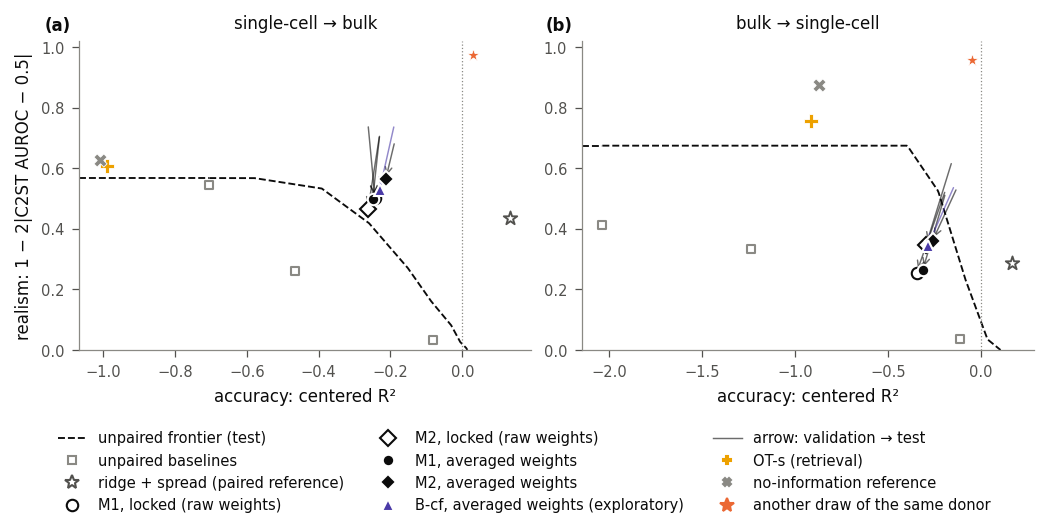

**On test, the strictly unpaired M1 is not distinguishable from the unpaired frontier in single-cell → bulk and lies inside it in bulk → single-cell, while real profiles that carry no information about the source lie beyond it.** From validation to test every model lost realism in both directions, and in single-cell → bulk the frontier fell further, so margins rose. Each panel places translations of the 119 test sources (14 donors) by accuracy (centered R², x-axis) and realism (1 − 2|AUROC − 0.5| of a classifier two-sample test, C2ST; y-axis); higher is better on both. (a) Single-cell → bulk; (b) bulk → single-cell. The dashed curve is the unpaired frontier on test: the best realism reached at each accuracy by blending two of mean shift, ComBat, CORAL and the training-target mean, all fit on the training halves. The frontier is flat to the left of its most realistic blend, and is drawn flat to the left axis edge. Gray squares: mean shift, ComBat and CORAL. Black: the strictly unpaired M1 (circles) and the weakly paired M2 (diamonds), open for the locked models (raw weights, chosen checkpoints, mean of seeds 0–2) and filled for averaged weights (mean over seeds 6–8 and steps 15,000, 17,500 and 20,000). Purple triangle: B-cf, the weakly paired model with cross-fitted composition labels (exploratory). Each arrow runs from a model's validation position to its test position. Open star: ridge + spread fit on all training pairs (paired reference). Yellow plus: OT-s, one training profile retrieved per source by optimal transport. Gray cross: one real training profile drawn at random per source (no-information reference). Orange star: another draw of the same donor. Dotted vertical line: centered R² = 0. The real and retrieved profiles beyond the frontier show that, on this realism measure, passing the frontier does not by itself mean that a translation carries information about its source. M1's single-cell → bulk point lies above the frontier, but its margin's 95% CI includes 0 (Table 7.1).

In [12]:
# Figure 7.1: the test accuracy-realism plane, with arrows from each model's validation position to its test position.
from matplotlib.lines import Line2D
p6m = pd.read_csv(paths.results_dir(6) / "plane_margins_val.csv")
fig, ax = figure("double", 3.4, 1, 2)
VALPOS = {}
for d in DIRS:
    for m in ("M1", "M2"):
        r = p3[(p3.direction == label(d)) & (p3.method == f"{m} (mean of 3 seeds)")].iloc[0]
        VALPOS[(m, d)] = (r["r2_centered"], r["realism"])
    for n in ("M1 (EMA)", "M2 (EMA)", "B-cf (EMA)"):
        VALPOS[(n, d)] = (ema_val(n, d, "r2_centered"), ema_val(n, d, "realism"))
STY = {"M1": dict(marker="o", mfc="white", mec=INK, color=INK), "M2": dict(marker="D", mfc="white", mec=INK, color=INK),
       "M1 (EMA)": dict(marker="o", mfc=INK, mec="white", color=INK), "M2 (EMA)": dict(marker="D", mfc=INK, mec="white", color=INK),
       "B-cf (EMA)": dict(marker="^", mfc=SERIES[6], mec="white", color=SERIES[6])}
for a, d in zip(ax, DIRS):
    env = envelope(FRONT[0][d])
    a.plot(env["r2_centered"], env["realism"], color=INK, lw=0.9, ls="--", zorder=1)
    for name in ("mean shift", "ComBat", "CORAL"):
        a.scatter(SC[(name, d)]["r2_centered"], SC[(name, d)]["realism"], s=18, marker="s", facecolor="white", edgecolor=MUTED, lw=1, zorder=2)
    for n, sty in STY.items():
        x0, y0 = VALPOS[(n, d)]; x1, y1 = SC[(n, d)]["r2_centered"], SC[(n, d)]["realism"]
        a.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color=sty["color"], lw=0.7, alpha=0.6), zorder=3)
        a.plot([x1], [y1], ls="", ms=5.5, zorder=5, **sty)
    a.scatter(SC[("ridge + spread", d)]["r2_centered"], SC[("ridge + spread", d)]["realism"], s=46, marker="*", facecolor="white", edgecolor=INK_2, lw=0.9, zorder=2)
    for n, mk, col in (("OT-s", "P", SERIES[3]), ("no-information reference", "X", MUTED), ("same-donor reference", "*", SERIES[1])):
        a.scatter(SC[(n, d)]["r2_centered"], SC[(n, d)]["realism"], s=40, marker=mk, color=col, edgecolor="white", lw=0.4, zorder=4)
    a.axvline(0, color=MUTED, lw=0.6, ls=":")
    x_lo = a.get_xlim()[0]                                     # display: F(r) is flat left of its most realistic blend, so draw it to the axis edge
    a.plot([x_lo, env["r2_centered"].iloc[0]], [env["realism"].iloc[0]] * 2, color=INK, lw=0.9, ls="--", zorder=1)
    a.set_xlim(left=x_lo)
    a.set(xlabel="accuracy: centered R²", ylabel="realism: 1 − 2|C2ST AUROC − 0.5|" if d == "S->B" else "", title=label(d), ylim=(0, 1.02))
handles = [Line2D([], [], color=INK, lw=0.9, ls="--", label="unpaired frontier (test)"), Line2D([], [], ls="", marker="s", mfc="white", mec=MUTED, label="unpaired baselines"),
           Line2D([], [], ls="", marker="*", ms=7, mfc="white", mec=INK_2, label="ridge + spread (paired reference)"),
           Line2D([], [], ls="", ms=5.5, label="M1, locked (raw weights)", **STY["M1"]), Line2D([], [], ls="", ms=5.5, label="M2, locked (raw weights)", **STY["M2"]),
           Line2D([], [], ls="", ms=5.5, label="M1, averaged weights", **STY["M1 (EMA)"]), Line2D([], [], ls="", ms=5.5, label="M2, averaged weights", **STY["M2 (EMA)"]),
           Line2D([], [], ls="", ms=5.5, label="B-cf, averaged weights (exploratory)", **STY["B-cf (EMA)"]),
           Line2D([], [], color=INK, lw=0.7, alpha=0.6, label="arrow: validation → test"),
           Line2D([], [], ls="", marker="P", color=SERIES[3], label="OT-s (retrieval)"), Line2D([], [], ls="", marker="X", color=MUTED, label="no-information reference"),
           Line2D([], [], ls="", marker="*", ms=7, color=SERIES[1], label="another draw of the same donor")]
fig.legend(handles=handles, loc="outside lower center", ncol=3)
panel_labels(ax)
save_show(fig, FIG, "7.1_test_plane")
show_caption("7.1_test_plane")

**On test, the strictly unpaired M1 is not distinguishable from the unpaired frontier in single-cell → bulk and lies inside it in bulk → single-cell, while real profiles that carry no information about the source lie beyond it.** From validation to test every model lost realism in both directions, and in single-cell → bulk the frontier fell further, so margins rose. Each panel places translations of the 119 test sources (14 donors) by accuracy (centered R², x-axis) and realism (1 − 2|AUROC − 0.5| of a classifier two-sample test, C2ST; y-axis); higher is better on both. (a) Single-cell → bulk; (b) bulk → single-cell. The dashed curve is the unpaired frontier on test: the best realism reached at each accuracy by blending two of mean shift, ComBat, CORAL and the training-target mean, all fit on the training halves. The frontier is flat to the left of its most realistic blend, and is drawn flat to the left axis edge. Gray squares: mean shift, ComBat and CORAL. Black: the strictly unpaired M1 (circles) and the weakly paired M2 (diamonds), open for the locked models (raw weights, chosen checkpoints, mean of seeds 0–2) and filled for averaged weights (mean over seeds 6–8 and steps 15,000, 17,500 and 20,000). Purple triangle: B-cf, the weakly paired model with cross-fitted composition labels (exploratory). Each arrow runs from a model's validation position to its test position. Open star: ridge + spread fit on all training pairs (paired reference). Yellow plus: OT-s, one training profile retrieved per source by optimal transport. Gray cross: one real training profile drawn at random per source (no-information reference). Orange star: another draw of the same donor. Dotted vertical line: centered R² = 0. The real and retrieved profiles beyond the frontier show that, on this realism measure, passing the frontier does not by itself mean that a translation carries information about its source. M1's single-cell → bulk point lies above the frontier, but its margin's 95% CI includes 0 (Table 7.1).

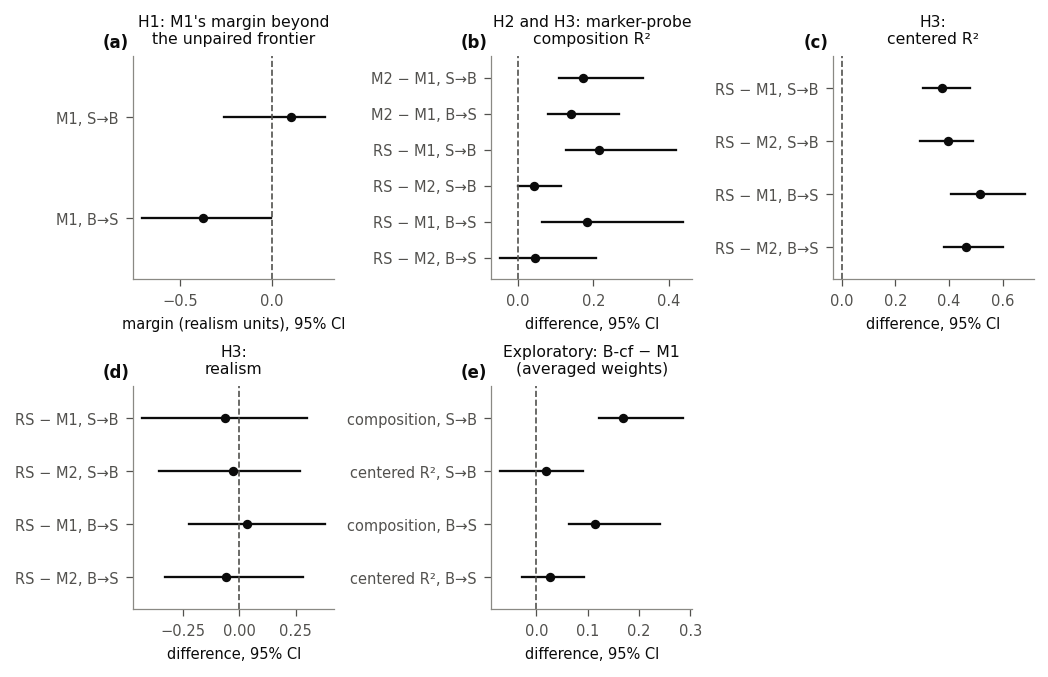

**H1 is not supported, H2 is supported in both directions, and paired regression is far more accurate than either GAN.** Point estimates and paired donor-bootstrap 95% CIs (1,000 resamples of the 14 test donors; 119 pairs), per direction (S→B, single-cell → bulk; B→S, bulk → single-cell). (a) H1: M1's margin beyond the unpaired frontier, in realism units; the frontier is rebuilt on each resample. (b) Marker-probe composition R²: H2, M2 minus M1, and H3, ridge + spread (RS, fit on all training pairs) minus each locked model. (c) H3, centered R². (d) H3, realism. (e) Exploratory: B-cf minus M1, both with averaged weights, in marker-probe composition R² ("composition") and centered R². The dashed line marks no difference. The four primary intervals are those of (a) and the first two rows of (b), reported per direction without multiplicity correction.

In [13]:
# Figure 7.2: the primary intervals and the H3 differences, one panel per metric; B-cf's primary intervals apart.
def ci_parts(s):
    lo, hi = (float(v) for v in s.split(" to "))
    return lo, hi
SHORT = {"S->B": "S→B", "B->S": "B→S", "single-cell → bulk": "S→B", "bulk → single-cell": "B→S"}
fig, axs = figure("double", 4.4, 2, 3)
ax = axs.ravel()
panels = [("H1: M1's margin beyond\nthe unpaired frontier", [(f"M1, {SHORT[d]}", h1_tab.iloc[i]["margin"], *ci_parts(h1_tab.iloc[i]["95% CI"])) for i, d in enumerate(DIRS)]),
          ("H2 and H3: marker-probe\ncomposition R²",
           [(f"M2 − M1, {SHORT[d]}", h2_tab.iloc[i]["difference"], *ci_parts(h2_tab.iloc[i]["95% CI"])) for i, d in enumerate(DIRS)] +
           [(f"RS − {r['ridge + spread minus']}, {SHORT[r['direction']]}", r["difference"], *ci_parts(r["95% CI"])) for _, r in h3_tab[h3_tab.metric == "marker composition R²"].iterrows()]),
          ("H3:\ncentered R²", [(f"RS − {r['ridge + spread minus']}, {SHORT[r['direction']]}", r["difference"], *ci_parts(r["95% CI"])) for _, r in h3_tab[h3_tab.metric == "centered R²"].iterrows()]),
          ("H3:\nrealism", [(f"RS − {r['ridge + spread minus']}, {SHORT[r['direction']]}", r["difference"], *ci_parts(r["95% CI"])) for _, r in h3_tab[h3_tab.metric == "realism"].iterrows()]),
          ("Exploratory: B-cf − M1\n(averaged weights)", [(f"{'composition' if r['metric'].startswith('marker') else 'centered R²'}, {SHORT[r['direction']]}", r["difference"], *ci_parts(r["95% CI"]))
                                                  for _, r in bcf_tab[bcf_tab.role == "primary"].iterrows()])]
for a, (title, rows) in zip(ax, panels):
    yy = np.arange(len(rows))[::-1]
    for y_, (lab_, e, lo, hi) in zip(yy, rows):
        a.plot([lo, hi], [y_, y_], color=INK, lw=1.1)
        a.plot([e], [y_], "o", color=INK, ms=3.5)
    a.axvline(0, **THRESHOLD)
    a.set_yticks(yy, [r[0] for r in rows], fontsize=7)
    a.set_ylim(-0.6, len(rows) - 0.4)
    a.set_title(title, fontsize=7.5)
    a.set_xlabel("margin (realism units), 95% CI" if title.startswith("H1") else "difference, 95% CI", fontsize=7)
ax[-1].axis("off")
panel_labels(ax[:5])
save_show(fig, FIG, "7.2_intervals")
show_caption("7.2_intervals")

**H1 is not supported, H2 is supported in both directions, and paired regression is far more accurate than either GAN.** Point estimates and paired donor-bootstrap 95% CIs (1,000 resamples of the 14 test donors; 119 pairs), per direction (S→B, single-cell → bulk; B→S, bulk → single-cell). (a) H1: M1's margin beyond the unpaired frontier, in realism units; the frontier is rebuilt on each resample. (b) Marker-probe composition R²: H2, M2 minus M1, and H3, ridge + spread (RS, fit on all training pairs) minus each locked model. (c) H3, centered R². (d) H3, realism. (e) Exploratory: B-cf minus M1, both with averaged weights, in marker-probe composition R² ("composition") and centered R². The dashed line marks no difference. The four primary intervals are those of (a) and the first two rows of (b), reported per direction without multiplicity correction.

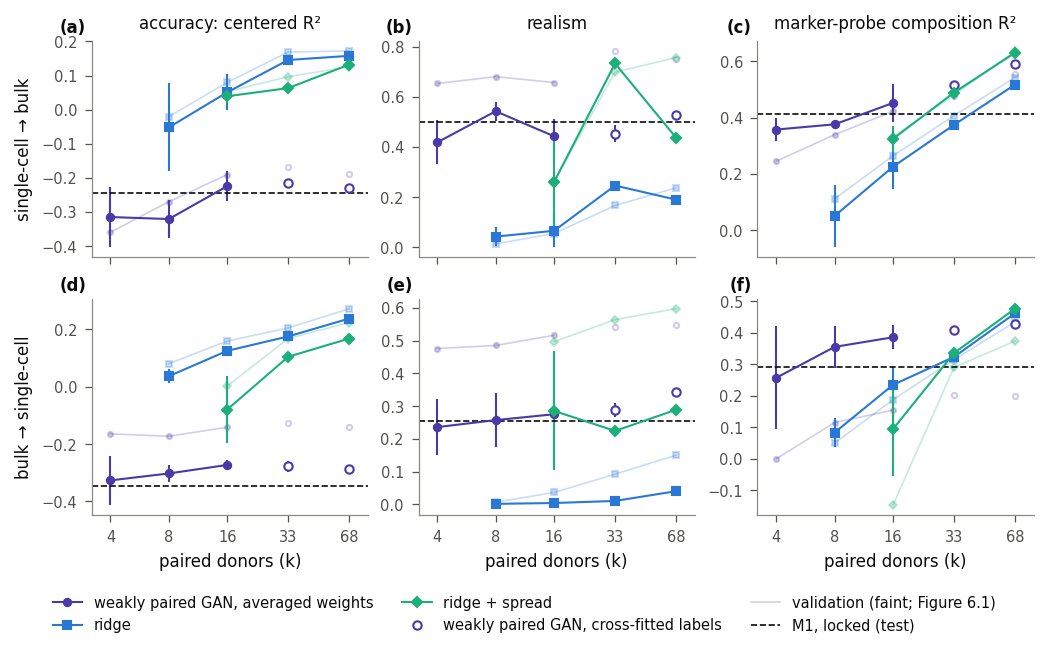

**On test, pairs buy far more accuracy as regression targets than as composition labels, and labels give more composition when few donors are paired.** Each panel plots one readout on the 119 test pairs (14 donors) against the number of paired donors k (log scale); higher is better. Columns: (a, d) accuracy (centered R²), (b, e) realism, (c, f) marker-probe composition R². Rows: (a–c) single-cell → bulk, (d–f) bulk → single-cell. Purple: the weakly paired CycleGAN whose composition labels come from a network trained on k donors' pairs (averaged weights; bars ± SD over seeds 6–8). At k = 4, 8 and 16 the donors are nested, so the SD includes the draw of donors. At k = 33 and 68 (open, unconnected markers) the labels are cross-fitted, so these points are not on the same footing; k = 68 is B-cf, whose bar is omitted. Blue and green: paired ridge and ridge + spread trained on the same k donors' pairs (± SD over the seeds' donor draws at k = 8 and 16; single fits at 33 and 68). Faint lines and markers: the same readouts on validation (Figure 6.1). Dashed line: the locked M1 on test. All points are scored on test only; nothing was chosen on them.

In [14]:
# Figure 7.3: what pairs buy on test, in the layout of Figure 6.1, with the validation values faint behind.
pbv = pd.read_csv(paths.results_dir(6) / "pairs_buy_val.csv")
KS = [4, 8, 16, 33, 68]
STY3 = {"weakly paired GAN (EMA)": dict(color=SERIES[6], marker="o"), "ridge": dict(color=SERIES[0], marker="s"), "ridge + spread": dict(color=SERIES[2], marker="D")}
METRICS = ["centered R²", "realism", "marker composition R²"]
fig, ax = figure("double", 4.2, 2, 3, sharex=True)
for i, d in enumerate(DIRS):
    for j, mname in enumerate(METRICS):
        a = ax[i, j]
        for meth, sty in STY3.items():
            v = pbv[(pbv.direction == label(d)) & (pbv.method == meth) & (pbv.metric == mname)].sort_values("k")
            t = pb_tab[(pb_tab.direction == label(d)) & (pb_tab.method == meth) & (pb_tab.metric == mname)].sort_values("k")
            if meth.startswith("weakly"):                      # display: k = 33 and 68 (cross-fitted labels) open and unconnected
                vf, tf = v[v.k > 16], t[t.k > 16]
                a.plot(vf.k, vf.value, ls="", ms=2.5, alpha=0.25, mfc="white", **sty)
                a.errorbar(tf.k, tf.value, yerr=np.nan_to_num(tf["seed SD"].to_numpy(float)), ls="", lw=1, ms=4, mfc="white", capsize=0, **sty)
                v, t = v[v.k <= 16], t[t.k <= 16]
            a.plot(v.k, v.value, lw=0.8, ms=2.5, alpha=0.25, **sty)
            a.errorbar(t.k, t.value, yerr=np.nan_to_num(t["seed SD"].to_numpy(float)), lw=1, ms=3.5, capsize=0, **sty)
        a.axhline(SC[("M1", d)]["r2_centered" if mname == "centered R²" else "realism" if mname == "realism" else "marker composition R²"], color=INK, lw=0.8, ls="--")
        a.set_xscale("log"); a.set_xticks(KS); a.set_xticklabels([str(k) for k in KS]); a.minorticks_off(); a.set_xlim(3.2, 85)
        a.set(xlabel="paired donors (k)" if i == 1 else "", ylabel=label(d) if j == 0 else "")
        if i == 0:
            a.set_title({"centered R²": "accuracy: centered R²", "realism": "realism", "marker composition R²": "marker-probe composition R²"}[mname])
handles = [Line2D([], [], lw=1, ms=3.5, **STY3[m], label=m.replace(" (EMA)", ", averaged weights")) for m in STY3] + \
          [Line2D([], [], ls="", marker="o", ms=4, mfc="white", color=SERIES[6], label="weakly paired GAN, cross-fitted labels"),
           Line2D([], [], lw=0.8, alpha=0.25, color=INK_2, label="validation (faint; Figure 6.1)"), Line2D([], [], lw=0.8, ls="--", color=INK, label="M1, locked (test)")]
fig.legend(handles=handles, loc="outside lower center", ncol=3)
panel_labels(ax.ravel())
save_show(fig, FIG, "7.3_what_pairs_buy_test")
show_caption("7.3_what_pairs_buy_test")

**On test, pairs buy far more accuracy as regression targets than as composition labels, and labels give more composition when few donors are paired.** Each panel plots one readout on the 119 test pairs (14 donors) against the number of paired donors k (log scale); higher is better. Columns: (a, d) accuracy (centered R²), (b, e) realism, (c, f) marker-probe composition R². Rows: (a–c) single-cell → bulk, (d–f) bulk → single-cell. Purple: the weakly paired CycleGAN whose composition labels come from a network trained on k donors' pairs (averaged weights; bars ± SD over seeds 6–8). At k = 4, 8 and 16 the donors are nested, so the SD includes the draw of donors. At k = 33 and 68 (open, unconnected markers) the labels are cross-fitted, so these points are not on the same footing; k = 68 is B-cf, whose bar is omitted. Blue and green: paired ridge and ridge + spread trained on the same k donors' pairs (± SD over the seeds' donor draws at k = 8 and 16; single fits at 33 and 68). Faint lines and markers: the same readouts on validation (Figure 6.1). Dashed line: the locked M1 on test. All points are scored on test only; nothing was chosen on them.

## 5. Conclusions

- **H1 is not supported.** The strictly unpaired CycleGAN is not distinguishable from the unpaired frontier in single-cell → bulk (+0.105, 95% CI −0.259 to 0.290) and lies inside it in bulk → single-cell (−0.372, 95% CI −0.705 to −0.006). Real profiles that carry no information about the source pass the same frontier, and on test M1 identifies its sample within the donor less often than its own start in single-cell → bulk (−0.090, 95% CI −0.162 to −0.019). On these readouts, without pairs, adversarial training bought realism no greater than blends of baselines reach, not information about the sample: M1 is less accurate than its start (−0.163, 95% CI −0.341 to −0.057, against mean shift; −0.235, 95% CI −0.359 to −0.128, against ComBat) and has less composition (0.414 against 0.498; 0.292 against 0.477; point estimates).
- **H2 is supported in both directions** (+0.174, 95% CI 0.108–0.331, and +0.140, 95% CI 0.079–0.267, in marker-probe composition R²), through networks trained on pairs that include the training donors' own; the single-cell → bulk gain carries the label that it partly fits the training readout. Labels from networks that never saw the labeled donor (B-cf, exploratory, averaged weights) exceed M1 by +0.169 (95% CI 0.122–0.286) and +0.115 (95% CI 0.064–0.240), not distinguishable from M2 with averaged weights, and carry the same label in both directions.
- **Pairs pay off far more as regression targets than as composition labels in accuracy:** ridge + spread is +0.395 (95% CI 0.293–0.488) and +0.463 (95% CI 0.383–0.600) more accurate than M2 (and +0.375, 95% CI 0.302–0.478, and +0.515, 95% CI 0.406–0.682, than M1), not distinguishable in realism. As composition labels, a few paired donors give more composition than regression on the same donors, and regression catches up with all 68 (descriptive; scored on test only).
- **The bulk → single-cell margins fell from validation to test for every model, with and without checkpoint selection** (by 0.20–0.35), while composition rose, consistent with differences between the validation and test donors; validation estimates of margin were optimistic in that direction.

These results are from one test evaluation on 14 donors.

## 6. Limitations

- **Fourteen test donors** give wide intervals: the H1 margins span about 0.55 and 0.70, and realism differences about ±0.3.
- **One cohort.** Every result is on Sound Life; other cohorts, platforms and pseudobulking choices are untested.
- **The realism measure** is a classifier test on the top 10 principal components. Real profiles that carry no information about the source pass the frontier on it, so a margin alone cannot show information.
- **Selection.** The locked settings and checkpoints were chosen on the 14 validation donors; the averaged-weight comparison removes checkpoint selection only, not the choice of setting.
- **B-cf** has no halving-1 check, and its design used validation results.
- **The pair-budget grid** was scored on test only, without intervals, and its k = 33 and 68 points are not on the same footing as the nested ones.

## 7. Reproducibility

- **Runtime and hardware:** the test run took 24 minutes on CPU, with 6 bootstrap workers of 4 CPU threads each; most of it is the H1 bootstrap (1,000 resamples × 2 directions). No translation model is trained here.
- **Determinism:** CPU only, with torch and the BLAS/OpenMP pools pinned to 4 threads and deterministic algorithms (`dgm.composition.deterministic`); fixed seeds for the donor bootstrap (seed 0), the OT-s draws and the no-information draws (seeds 0–2). A repeated validation dry run reproduces every CSV byte for byte.
- **Code:** `dgm/testeval.py` (the per-resample frontier and margins, the pre-stated reading rules), `dgm/analysis.py` and `dgm/ot.py` (Phase 6), and the shared modules of Phases 1–5. Known-answer tests: `python -m tests.test_phase7`.
- **Running it:** `PHASE7_DRY=1` runs on validation instead of test (it never reads a test row), checks the Phase 1–6 validation values it reproduces and writes to `data/processed/phase7/dry_results`; `PHASE7_NBOOT` sets its number of resamples. `PHASE7_TEST=1` runs on test with 1,000 resamples, and only with the code whose hash was recorded in `results/phase7/audited_code_hash.txt` before the test run; the scoring run used code 2bba0b3f51dd55d6 and the presentation re-run code 15367eb6ad547608 (display-only changes); each test run appends a record to `results/phase7/test_touch.json`.
- **Inputs:** the Phase 3 model files and the Phase 5 run caches, each checked against its registry hash or per-run table before scoring; the frozen evaluators, composition networks and marker probes of Phases 1 and 2; the Phase 1, 3, 5 and 6 result tables.
- **Caches** in `data/processed/phase7`: the frozen fits in `fits/`, keyed by their training rows and the baseline code; the H1 bootstrap in `h1_boot_<test|dry>_<code hash>_<resamples>.pkl`. Delete a file to recompute it.

**Outputs in `results/phase7/`:**
- `h1_test.csv` (Table 7.1), `h1_superseded_test.csv` (Table 7.2), `h1_within_donor_test.csv` (Table 7.3), `references_test.csv` (Table 7.4);
- `h2_test.csv` (Table 7.5), `h2_suspect_test.csv` (Table 7.6), `h3_test.csv` (Table 7.7), `models_test.csv` (Tables 7.8, 7.9 and 7.12);
- `shrinkage_test.csv` (Table 7.10), `bcf_test.csv` (Table 7.11), `pairs_buy_test.csv` (Table 7.13);
- `figures/`: Figures 7.1–7.3 as PNG and PDF, with their captions in `captions.md`.

## References

- Cuturi, M. Sinkhorn distances: lightspeed computation of optimal transport. *NeurIPS* (2013).
- Gretton, A., Borgwardt, K. M., Rasch, M. J., Schölkopf, B. & Smola, A. A kernel two-sample test. *Journal of Machine Learning Research* 13, 723–773 (2012).
- Johnson, W. E., Li, C. & Rabinovic, A. Adjusting batch effects in microarray expression data using empirical Bayes methods. *Biostatistics* 8, 118–127 (2007).
- Lopez-Paz, D. & Oquab, M. Revisiting classifier two-sample tests. *ICLR* (2017).
- Sun, B., Feng, J. & Saenko, K. Return of frustratingly easy domain adaptation. *AAAI* (2016).
- Zhu, J.-Y., Park, T., Isola, P. & Efros, A. A. Unpaired image-to-image translation using cycle-consistent adversarial networks. *ICCV* (2017).